# Pre-processing the web log

In [41]:
LOG_PATH = "CAB330_asm2_datasets 2/Dataset4Task4_26.txt"

with open(LOG_PATH, "r", encoding="utf-8", errors="replace") as log_file:
    lines = [line.rstrip("\r\n") for line in log_file]

print(f"Lines read: {len(lines):,}")
for line in lines[:10]:
    print()
    print(line)

Lines read: 15,000

54.36.149.41 - - [22/Jan/2019:03:56:14 +0330] "GET /filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA%A9%D8%B3%D9%84,27|%DA%A9%D9%85%D8%AA%D8%B1%20%D8%A7%D8%B2%205%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA%A9%D8%B3%D9%84,p53 HTTP/1.1" 200 30577 "-" "Mozilla/5.0 (compatible; AhrefsBot/6.1; +http://ahrefs.com/robot/)" "-"

31.56.96.51 - - [22/Jan/2019:03:56:16 +0330] "GET /image/60844/productModel/200x200 HTTP/1.1" 200 5667 "https://www.zanbil.ir/m/filter/b113" "Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build/HuaweiALE-L21) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/66.0.3359.158 Mobile Safari/537.36" "-"

31.56.96.51 - - [22/Jan/2019:03:56:16 +0330] "GET /image/61474/productModel/200x200 HTTP/1.1" 200 5379 "https://www.zanbil.ir/m/filter/b113" "Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build/HuaweiALE-L21) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/66.0.3359.158 Mobile Safari/537.36" "-"

40.77.167.129 - - [22/Jan/2019:03:56:17 +0330] "GET /image/14925/productModel/100x

The format of each log line:
```text
ip ident auth [time] "method path proto" status size "referrer" "user_agent" "extra"
```

## Defining the format of one log line

In [42]:
import re

LINE_PATTERN = re.compile(
    r'^(\S+) (\S+) (\S+) \[([^\]]+)\] "([^"]*)" (\S+) (\S+) "([^"]*)" "([^"]*)" "([^"]*)"$'
)

COLUMNS = [
    "ip",
    "ident",
    "auth",
    "time",
    "method",
    "path",
    "proto",
    "status",
    "size",
    "referrer",
    "user_agent",
]

## Parse every line into fields

In [43]:
records = []
unparsed = []

for line_number, line in enumerate(lines, start=1):
    match = LINE_PATTERN.match(line)
    if match is None:
        unparsed.append(line_number)
        continue

    ip, ident, auth, time, request, status, size, referrer, user_agent, _extra = match.groups()
    method, _, remainder = request.partition(" ")
    path, _, proto = remainder.rpartition(" ")
    records.append(
        (ip, ident, auth, time, method, path, proto, status, size, referrer, user_agent)
    )

print(f"Rows parsed: {len(records):,}")
print(f"Lines that did not match the pattern: {len(unparsed)}")

# checked _extra and contains ip addresses. Chose to ignore

Rows parsed: 15,000
Lines that did not match the pattern: 0


## Build the DataFrame

In [44]:
import pandas as pd


logs = pd.DataFrame(records, columns=COLUMNS).astype(object)
logs.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ip          15000 non-null  object
 1   ident       15000 non-null  object
 2   auth        15000 non-null  object
 3   time        15000 non-null  object
 4   method      15000 non-null  object
 5   path        15000 non-null  object
 6   proto       15000 non-null  object
 7   status      15000 non-null  object
 8   size        15000 non-null  object
 9   referrer    15000 non-null  object
 10  user_agent  15000 non-null  object
dtypes: object(11)
memory usage: 1.3+ MB


# Cleaning the data

## Convert the time column into a datetime object

In [45]:
logs["Datetime"] = pd.to_datetime(logs["time"], format="%d/%b/%Y:%H:%M:%S %z")

print(f"Timestamps parsed: {logs['Datetime'].notna().sum():,} of {len(logs):,}")
print(f"First request: {logs['Datetime'].min()}")
print(f"Last request:  {logs['Datetime'].max()}")
print(f"Time span:     {logs['Datetime'].max() - logs['Datetime'].min()}")

Timestamps parsed: 15,000 of 15,000
First request: 2019-01-22 03:56:14+03:30
Last request:  2019-01-22 04:56:13+03:30
Time span:     0 days 00:59:59


## Finding missing values

In [46]:
logs = logs.replace("-", pd.NA)

missing = logs.isna().sum().rename("missing").to_frame()
missing["share_%"] = (missing["missing"] / len(logs) * 100).round(2)
missing

,missing,share_%
ip,0,0.00
ident,15000,100.00
auth,15000,100.00
time,0,0.00
method,0,0.00
path,0,0.00
proto,0,0.00
status,0,0.00
size,0,0.00
referrer,8234,54.89


## Remove attributes which are no longer required

In [47]:
cleaned = logs.drop(columns=["ident", "auth", "referrer", "size", "time"]).copy()
cleaned["status"] = cleaned["status"].astype(int)

print(f"Rows: {len(cleaned):,}")
print(f"Columns: {list(cleaned.columns)}")

Rows: 15,000
Columns: ['ip', 'method', 'path', 'proto', 'status', 'user_agent', 'Datetime']


Note: referrer might be useful for providing information about relationships between pages, however since 54.89% are missing, it is safer to just remove them to also avoid bias

In [48]:
cleaned = cleaned.sort_values("Datetime", ascending=False, kind="mergesort").reset_index(drop=True)

preview = cleaned[["ip", "method", "path", "proto", "status", "Datetime"]].head(10).copy()
preview["path"] = preview["path"].str.slice(0, 55)
print(preview.to_string(index=True))

                ip method                                                     path     proto  status                  Datetime
0      91.99.72.15    GET                               /product/31055?model=60906  HTTP/1.1     200 2019-01-22 04:56:13+03:30
1    207.46.13.136    GET                             /filter?f=b2%2Cb484%2Cp1&o=b  HTTP/1.1     302 2019-01-22 04:56:13+03:30
2  146.185.133.111    GET                        /image/61956/productModel/200x200  HTTP/1.1     200 2019-01-22 04:56:13+03:30
3  146.185.133.111    GET                        /image/60701/productModel/200x200  HTTP/1.1     200 2019-01-22 04:56:13+03:30
4     54.36.149.13    GET  /filter/p11673%2Cv1%7C%D8%A2%D8%A8%DB%8C%20%D9%86%D9%81  HTTP/1.1     302 2019-01-22 04:56:12+03:30
5   108.26.219.129    GET                            /apple-touch-icon-120x120.png  HTTP/1.1     404 2019-01-22 04:56:12+03:30
6    66.249.66.194    GET            /m/browse/pens-and-pencell/%D9%82%D9%84%D9%85  HTTP/1.1     200 2019-01-22

# Removing image and audio requests

In [49]:
def path_segments(url_path):
    if not isinstance(url_path, str):
        return []
    return [segment for segment in url_path.split("?", 1)[0].split("/") if segment]

In [50]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".gif", ".ico", ".webp", ".svg", ".bmp"}
AUDIO_EXTENSIONS = {".mp3", ".wav", ".ogg", ".oga", ".aac", ".m4a", ".flac", ".wma"}
IMAGE_SEGMENTS = {"image", "images", "productimage"}
AUDIO_SEGMENTS = {"audio", "sound", "mp3"}

def media_kind(url_path):
    """Return 'image', 'audio', or '' when the request is a page request."""
    segments = [segment.lower() for segment in path_segments(url_path)]
    if not segments:
        return ""

    last = segments[-1]
    extension = "." + last.rsplit(".", 1)[-1] if "." in last else ""

    if any(segment in IMAGE_SEGMENTS for segment in segments):
        return "image"
    if segments[:2] == ["settings", "logo"]:
        return "image"
    if extension in IMAGE_EXTENSIONS or last.startswith("apple-touch-icon"):
        return "image"
    if last == "favicon.ico":
        return "image"
    if extension in AUDIO_EXTENSIONS or any(segment in AUDIO_SEGMENTS for segment in segments):
        return "audio"
    return ""


def image_reason(url_path):
    """Short explanation of why a path was classified as an image."""
    segments = [segment.lower() for segment in path_segments(url_path)]
    if not segments:
        return "missing path"

    last = segments[-1]
    extension = "." + last.rsplit(".", 1)[-1] if "." in last else ""

    if any(segment in IMAGE_SEGMENTS for segment in segments):
        return "image path segment"
    if segments[:2] == ["settings", "logo"]:
        return "shop logo"
    if extension in IMAGE_EXTENSIONS:
        return "image file extension"
    if last.startswith("apple-touch-icon") or last == "favicon.ico":
        return "browser icon"
    return "other"

## Number of image and audio requests

In [51]:
cleaned["media"] = cleaned["path"].map(media_kind)

media_counts = cleaned["media"].value_counts()
print(f"Image requests: {int(media_counts.get('image', 0)):,}")
print(f"Audio requests: {int(media_counts.get('audio', 0)):,}")
print()

image_rows = cleaned.loc[cleaned["media"] == "image"]
print("How the image requests were recognised:")
print(image_rows["path"].map(image_reason).value_counts().to_string())

Image requests: 6,780
Audio requests: 0

How the image requests were recognised:
path
image path segment      6203
shop logo                384
image file extension     193


## Remove the media requests

In [52]:
pages = cleaned.loc[
    cleaned["media"] == "",
    ["ip", "method", "path", "proto", "status", "Datetime", "user_agent"]
].copy()

print(f"Rows before removing media requests: {len(cleaned):,}")
print(f"Rows after removing media requests: {len(pages):,}")
print(f"Columns kept: {len(pages.columns)}")

Rows before removing media requests: 15,000
Rows after removing media requests: 8,220
Columns kept: 7


# Identifying user sessions
A user session is a sequence of requests made by one IP address in which no two consecutive requests are more that 30 minutes apart (defined in task specification).

A new session starts when either condition holds:
1. The request is the first one seen from that IP
2. the time since that IP address's previous request is greater than 30 minutes

This cannot separate two people behind a proxy, or one person switching networks as IP is the only identifier.

## Sort by client and time, then measure gap

In [53]:
SESSION_TIMEOUT = pd.Timedelta(minutes=30)

pages = pages.sort_values(["ip", "Datetime", "path"], kind="mergesort").reset_index(drop=True)
pages["gap"] = pages.groupby("ip", sort=False)["Datetime"].diff()
pages["new_session"] = pages["gap"].isna() | (pages["gap"] > SESSION_TIMEOUT)

print(f"Page requests in time order: {len(pages):,}")
print(f"Requests that begin in a new session: {int(pages['new_session'].sum()):,}")

Page requests in time order: 8,220
Requests that begin in a new session: 602


## Assign the SessionID

In [54]:
pages["session_index"] = pages.groupby("ip", sort=False)["new_session"].cumsum()

session_starts = (
    pages.loc[pages["new_session"], ["ip", "session_index", "Datetime"]]
    .sort_values(["Datetime", "ip"], kind="mergesort")
    .reset_index(drop=True)
)
session_starts["SessionID"] = session_starts.index + 1

pages = pages.merge(
    session_starts[["ip", "session_index", "SessionID"]],
    on=["ip", "session_index"],
    how="left"
)

print(f"Sessions identified: {pages['SessionID'].nunique():,}")

Sessions identified: 602


# Assign the Steps column

In [55]:
pages = pages.sort_values(["SessionID", "Datetime", "path"], kind="mergesort").reset_index(drop=True)
pages["Steps"] = pages.groupby("SessionID", sort=False).cumcount() + 1

pages[["ip", "path", "Datetime", "SessionID", "Steps"]].head(5)

,ip,path,Datetime,SessionID,Steps
0,54.36.149.41,/filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C...,2019-01-22 03:56:14+03:30,1,1
1,54.36.149.41,/login/auth?forwardUri=%2Ffilter%2Fb33%2Cp47%2...,2019-01-22 04:06:30+03:30,1,2
2,54.36.149.41,/blog/cosmetic/%DA%86%DA%AF%D9%88%D9%86%D9%87-...,2019-01-22 04:08:40+03:30,1,3
3,91.99.72.15,/product/31893/62100/%D8%B3%D8%B4%D9%88%D8%A7%...,2019-01-22 03:56:17+03:30,2,1
4,91.99.72.15,/product/10075/13903/%D9%85%D8%A7%DB%8C%DA%A9%...,2019-01-22 03:56:19+03:30,2,2


## Display the session table
Note: Paths are not decoded as they are in non-english languages

In [56]:
session_view = pages.sort_values(["Datetime", "SessionID", "Steps"], kind="mergesort")
preview = session_view[
    ["ip", "method", "path", "proto", "status", "Datetime", "SessionID", "Steps"]
].head(15).copy()

preview["path"] = preview["path"].str.slice(0, 50)
print(preview.to_string(index=False))

           ip method                                               path    proto  status                  Datetime  SessionID  Steps
 54.36.149.41    GET /filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA% HTTP/1.1     200 2019-01-22 03:56:14+03:30          1      1
  91.99.72.15    GET /product/31893/62100/%D8%B3%D8%B4%D9%88%D8%A7%D8%B HTTP/1.1     200 2019-01-22 03:56:17+03:30          2      1
207.46.13.136    GET                                     /product/10214 HTTP/1.1     200 2019-01-22 03:56:18+03:30          3      1
66.249.66.194    GET /filter/b41,b665,c150%7C%D8%A8%D8%AE%D8%A7%D8%B1%D HTTP/1.1     200 2019-01-22 03:56:18+03:30          4      1
  91.99.72.15    GET /product/10075/13903/%D9%85%D8%A7%DB%8C%DA%A9%D8%B HTTP/1.1     200 2019-01-22 03:56:19+03:30          2      2
207.46.13.136    GET                                     /product/14926 HTTP/1.1     404 2019-01-22 03:56:19+03:30          3      2
178.253.33.51    GET /m/product/32574/62991/%D9%85%D8%A7%D8%B4%DB%8C%

## Session summary

In [57]:
session_lengths = pages.groupby("SessionID").size()

print(f"Sessions: {len(session_lengths):,}")
print(
    f"Requests per session: mean {session_lengths.mean():.2f}, "
    f"median {session_lengths.median():.0f}, maximum {session_lengths.max():,}"
)
print(f"Sessions with one request: {int((session_lengths == 1).sum()):,}")
print(f"Sessions with at least five requests: {int((session_lengths >= 5).sum()):,}")

Sessions: 602
Requests per session: mean 13.65, median 2, maximum 2,018
Sessions with one request: 274
Sessions with at least five requests: 113


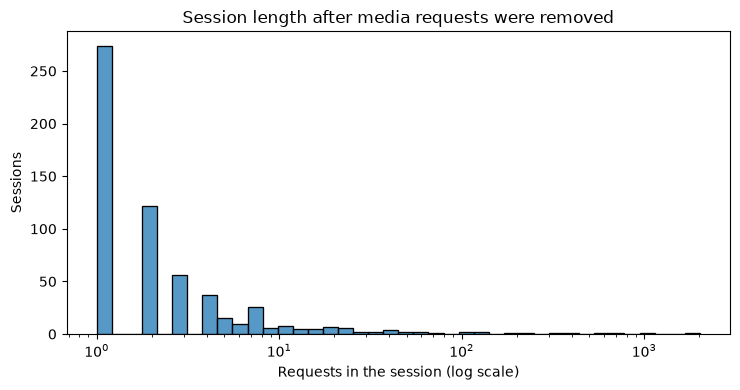

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.histplot(session_lengths, bins=40, log_scale=(True, False), ax=ax)
ax.set_title("Session length after media requests were removed")
ax.set_xlabel("Requests in the session (log scale)")
ax.set_ylabel("Sessions")
fig.tight_layout()
plt.show()

# Unsupervised learning on the sessions

In [59]:
CONTENT_PAGE_TYPES = {
    "product", "filter", "browse", "blog", "search", "basket",
    "login", "customer", "article", "comparison", "order",
}

def page_type(url_path):
    '''Map a request path to its page type, or None when it is not a content page.'''
    segments = [segment.lower() for segment in path_segments(url_path)]
    if not segments:
        return "home"

    first = segments[0]
    if first == "m":
        if len(segments) == 1:
            return "m/home"
        return "m/" + segments[1] if segments[1] in CONTENT_PAGE_TYPES else None
    return first if first in CONTENT_PAGE_TYPES else None


pages["page_type"] = pages["path"].map(page_type)

print(f"Requests on a content page: {int(pages['page_type'].notna().sum()):,}")
print(f"Requests on other URLs (static, helper, robots): {int(pages['page_type'].isna().sum()):,}")
print(f"Sessions containing a content page: {pages.dropna(subset=['page_type'])['SessionID'].nunique():,}")
print()
print(pages["page_type"].value_counts(dropna=False).to_string())

Requests on a content page: 7,443
Requests on other URLs (static, helper, robots): 777
Sessions containing a content page: 550

page_type
filter        4025
product       1129
m/filter       938
NaN            777
m/product      287
home           242
m/browse       230
blog           174
browse         156
m/article       58
m/home          34
search          31
basket          30
customer        29
m/search        26
article         25
login           20
comparison       7
order            2


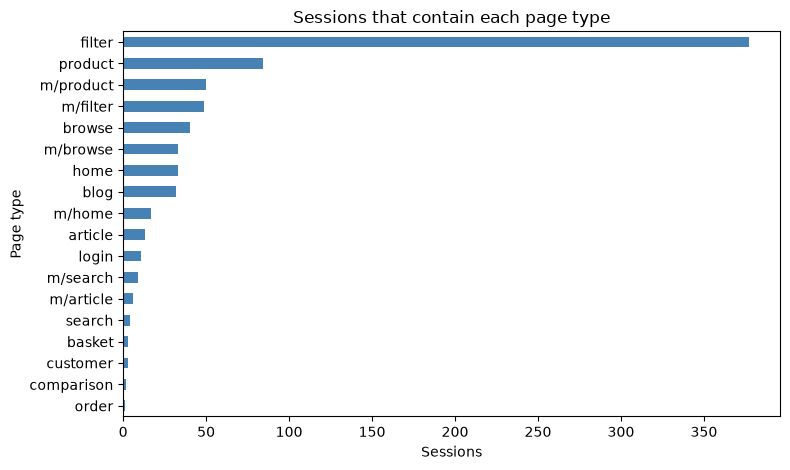

In [60]:
session_frequency = (
    pages.dropna(subset=["page_type"])
    .groupby("page_type")["SessionID"]
    .nunique()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 4.8))
session_frequency.plot.barh(ax=ax, color="steelblue")
ax.set_title("Sessions that contain each page type")
ax.set_xlabel("Sessions")
ax.set_ylabel("Page type")
fig.tight_layout()
plt.show()

## Build session baskets

In [61]:
baskets = (
    pages.dropna(subset=["page_type"])
    .groupby("SessionID")["page_type"]
    .apply(lambda values: sorted(set(values)))
)
baskets = [basket for basket in baskets if basket]

print(f"Sessions used as baskets: {len(baskets):,}")
print(f"Baskets with two or more page types: {sum(len(basket) >= 2 for basket in baskets):,}")
print(f"Distinct page types used as items: {len({item for basket in baskets for item in basket})}")

Sessions used as baskets: 550
Baskets with two or more page types: 124
Distinct page types used as items: 18


## Apply Apriori

In [62]:
from apyori import apriori

MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.1

results = list(apriori(baskets, min_support=MIN_SUPPORT, min_confidence=MIN_CONFIDENCE))

print(f"Frequent itemsets: {len(results):,}")
print(f"min_support {MIN_SUPPORT} means an itemset must appear in at least {MIN_SUPPORT * len(baskets):.0f} sessions")
print(f"min_confidence: {MIN_CONFIDENCE}")

Frequent itemsets: 13
min_support 0.02 means an itemset must appear in at least 11 sessions
min_confidence: 0.1


## Convert results into rule table

In [63]:
def convert_apriori_results(results):
    '''Convert apyori results into the Left_side/Right_side/Support/Confidence/Lift table.'''
    rules = []
    for rule_set in results:
        for rule in rule_set.ordered_statistics:
            if not rule.items_base or not rule.items_add:
                continue
            rules.append([
                ",".join(sorted(rule.items_base)),
                ",".join(sorted(rule.items_add)),
                rule_set.support,
                rule.confidence,
                rule.lift,
            ])

    table = pd.DataFrame(rules, columns=["Left_side", "Right_side", "Support", "Confidence", "Lift"])
    table = table.sort_values(["Lift", "Confidence"], ascending=False).reset_index(drop=True)
    table["Rule"] = table["Left_side"] + " -> " + table["Right_side"]
    return table


rules = convert_apriori_results(results)

print(f"Association rules with items on both sides: {len(rules)}")
print(rules[["Left_side", "Right_side", "Support", "Confidence", "Lift"]].to_string(index=False))

Association rules with items on both sides: 26
         Left_side         Right_side  Support  Confidence     Lift
m/filter,m/product           m/browse 0.023636    0.565217 9.420290
          m/browse m/filter,m/product 0.023636    0.393939 9.420290
m/browse,m/product           m/filter 0.023636    0.812500 9.119898
          m/filter m/browse,m/product 0.023636    0.265306 9.119898
         m/product  m/browse,m/filter 0.023636    0.260000 8.411765
 m/browse,m/filter          m/product 0.023636    0.764706 8.411765
          m/browse           m/filter 0.030909    0.515152 5.782313
          m/filter           m/browse 0.030909    0.346939 5.782313
         m/product           m/browse 0.029091    0.320000 5.333333
          m/browse          m/product 0.029091    0.484848 5.333333
          m/filter          m/product 0.041818    0.469388 5.163265
         m/product           m/filter 0.041818    0.460000 5.163265
            browse     filter,product 0.023636    0.325000 4.062500
 

## Rule with highest confidence

In [64]:
best_confidence = rules.loc[rules["Confidence"].idxmax()]
print(f"Highest confidence: {best_confidence['Confidence']:.4f}")
print(best_confidence[["Left_side", "Right_side", "Support", "Confidence", "Lift"]].to_string())

Highest confidence: 0.9231
Left_side      article
Right_side      filter
Support       0.021818
Confidence    0.923077
Lift          1.346664


## Rule with highest lift

In [65]:
best_lift = rules.loc[rules["Lift"].idxmax()]
print(f"Highest lift: {best_lift['Lift']:.4f}")
print(best_lift[["Left_side", "Right_side", "Support", "Confidence", "Lift"]].to_string())

Highest lift: 9.4203
Left_side     m/filter,m/product
Right_side              m/browse
Support                 0.023636
Confidence              0.565217
Lift                     9.42029


## Plot support, confidence, lift

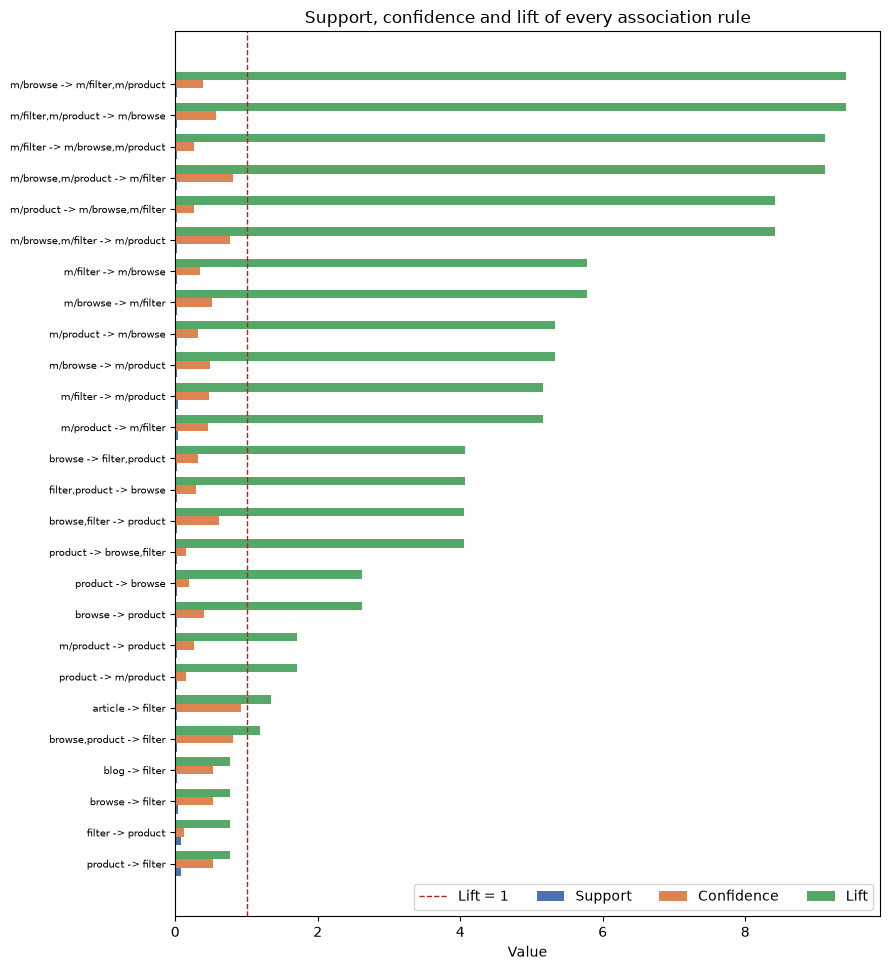

In [66]:
plot_rules = rules.sort_values("Lift").reset_index(drop=True)
positions = [float(position) for position in range(len(plot_rules))]
bar_height = 0.27

fig, ax = plt.subplots(figsize=(9, 0.30 * len(plot_rules) + 2))
for offset, column, colour in (
    (-bar_height, "Support", "#4C72B0"),
    (0.0, "Confidence", "#DD8452"),
    (bar_height, "Lift", "#55A868"),
):
    ax.barh(
        [position + offset for position in positions],
        plot_rules[column],
        height=bar_height,
        label=column,
        color=colour,
    )

ax.axvline(1, color="firebrick", linestyle="--", linewidth=1, label="Lift = 1")
ax.set_yticks(positions)
ax.set_yticklabels(plot_rules["Rule"], fontsize=7.5)
ax.set_xlabel("Value")
ax.set_title("Support, confidence and lift of every association rule")
ax.legend(ncol=4, loc="lower right")
fig.tight_layout()
plt.show()

## Keep the rules with lift at least 1

In [67]:
positive_rules = rules.loc[rules["Lift"] >= 1].sort_values("Lift", ascending=False).reset_index(drop=True)

print(f"Rules with lift >= 1: {len(positive_rules)} of {len(rules)}")
print(positive_rules[["Left_side", "Right_side", "Support", "Confidence", "Lift"]].to_string(index=False))

Rules with lift >= 1: 22 of 26
         Left_side         Right_side  Support  Confidence     Lift
m/filter,m/product           m/browse 0.023636    0.565217 9.420290
          m/browse m/filter,m/product 0.023636    0.393939 9.420290
m/browse,m/product           m/filter 0.023636    0.812500 9.119898
          m/filter m/browse,m/product 0.023636    0.265306 9.119898
         m/product  m/browse,m/filter 0.023636    0.260000 8.411765
 m/browse,m/filter          m/product 0.023636    0.764706 8.411765
          m/browse           m/filter 0.030909    0.515152 5.782313
          m/filter           m/browse 0.030909    0.346939 5.782313
         m/product           m/browse 0.029091    0.320000 5.333333
          m/browse          m/product 0.029091    0.484848 5.333333
          m/filter          m/product 0.041818    0.469388 5.163265
         m/product           m/filter 0.041818    0.460000 5.163265
            browse     filter,product 0.023636    0.325000 4.062500
    filter,produc

# How much is crawler traffic

In [68]:
CRAWLER_PATTERN = re.compile(
    r"bot|spider|crawler|slurp|ahrefs|semrush|dotbot|petalbot|yandex|baidu|sogou|duckduck",
    re.IGNORECASE,
)
pages["is_crawler"] = pages["user_agent"].str.contains(CRAWLER_PATTERN, na=False)

session_crawler_share = pages.groupby("SessionID")["is_crawler"].mean()
human_sessions = session_crawler_share[session_crawler_share < 0.5].index
human_baskets = [
    basket
    for basket in (
        pages.loc[pages["SessionID"].isin(human_sessions)]
        .dropna(subset=["page_type"])
        .groupby("SessionID")["page_type"]
        .apply(lambda values: sorted(set(values)))
    )
    if basket
]

print(f"Requests from a crawler user agent: {int(pages['is_crawler'].sum()):,} of {len(pages):,}")
print(f"Sessions that are not majority crawler: {len(human_sessions):,} of {len(session_crawler_share):,}")
print(f"Human baskets with a content page: {len(human_baskets):,}")

Requests from a crawler user agent: 5,570 of 8,220
Sessions that are not majority crawler: 180 of 602
Human baskets with a content page: 135


In [69]:
def rule_metrics(basket_list, left_items, right_items):
    '''Support, confidence and lift of left -> right, computed directly on baskets.'''
    n = len(basket_list)
    left = sum(1 for basket in basket_list if left_items <= set(basket))
    both = sum(1 for basket in basket_list if (left_items | right_items) <= set(basket))
    right = sum(1 for basket in basket_list if right_items <= set(basket))

    support = both / n
    confidence = both / left if left else 0.0
    lift = confidence / (right / n) if right else 0.0
    return support, confidence, lift


left = frozenset({"m/filter", "m/product"})
right = frozenset({"m/browse"})

print("Rule: {m/filter, m/product} -> {m/browse}")
for name, basket_list in (("all sessions", baskets), ("human sessions", human_baskets)):
    support, confidence, lift = rule_metrics(basket_list, left, right)
    print(f"  {name}: support {support:.3f}, confidence {confidence:.3f}, lift {lift:.2f}")

Rule: {m/filter, m/product} -> {m/browse}
  all sessions: support 0.024, confidence 0.565, lift 9.42
  human sessions: support 0.089, confidence 0.600, lift 2.61
